# 03 · Reducción de dimensionalidad, clustering y validación

**Objetivo:** segmentar a los 4.324 clientes con **K-Means, GMM y DBSCAN (más HDBSCAN)**, usar **PCA y t-SNE**,
validar los clusters (métricas internas, estabilidad, concordancia con el baseline RFM y criterio de negocio)
y elegir un modelo final.

**Entrada:** `clientes_features.parquet` y `preprocesador.joblib` (notebook 02). Variables de clustering:
`recency`, `frequency`, `ticket_promedio`, `productos_distintos`, en escala log1p, winsorizadas p1–p99 y
estandarizadas.

**Dos espacios de trabajo:**
- `Z`: con winsorizado. Se usa para K-Means, GMM y PCA, y es el espacio común donde se comparan las métricas.
- `Zn`: sin winsorizado. Se usa para DBSCAN y HDBSCAN, para que los clientes extremos puedan aparecer como
  ruido (lo prometido en el notebook 02).

La lógica está en `src/segmentacion/modelado.py`, `evaluacion.py` y `perfilamiento.py`.

In [1]:
import json
import sys
import warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
from sklearn.cluster import KMeans

from segmentacion import config
from segmentacion.evaluacion import ari, estabilidad_submuestreo, matriz_ari, metricas_internas
from segmentacion.features import VARIABLES_CLUSTERING, construir_preprocesador
from segmentacion.modelado import (ajustar_dbscan, ajustar_gmm, ajustar_hdbscan, ajustar_kmeans, ajustar_pca,
                                   barrido_gmm, barrido_kmeans, calcular_tsne, cargas_pca, descuantizar,
                                   distancias_k_vecinos, indice_codo, ordenar_clusters_kmeans, resumen_densidad,
                                   tabla_varianza_pca, VARIANZA_EMPIRICA_MINIMA)
from segmentacion.perfilamiento import resumen_segmentos
from segmentacion.visualizacion import COLOR_NEUTRO, COLOR_PRINCIPAL, COLOR_SECUNDARIO, estilo, guardar_figura

warnings.filterwarnings("ignore", category=FutureWarning)
estilo()
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

clientes = pd.read_parquet(config.PARQUET_CLIENTES)
preprocesador = joblib.load(config.PREPROCESADOR)
X = clientes[VARIABLES_CLUSTERING]
Z = preprocesador.transform(X)
pre_sin_winsor = construir_preprocesador(X, winsorizar=False)
Zn = pre_sin_winsor.transform(X)
F = clientes["frequency"].to_numpy()
IDX_F = VARIABLES_CLUSTERING.index("frequency")
K = list(range(2, 11))

# Copia con frequency descuantizada (ruido uniforme ±0,5): SOLO para diagnosticar el efecto de los empates.
X_desc = X.assign(frequency=descuantizar(X["frequency"]))
Z_desc, Zn_desc = preprocesador.transform(X_desc), pre_sin_winsor.transform(X_desc)
print(f"Z: {Z.shape} · Zn: {Zn.shape}")

Z: (4324, 4) · Zn: (4324, 4)


## 1. Punto de partida: empates en `frequency`

`frequency` es un conteo entero, y un tercio de los clientes tiene exactamente el mismo valor (1). En el espacio
estandarizado esos clientes no forman una nube, sino un **plano**: todos tienen la misma coordenada en esa
dimensión. Esto puede engañar a los métodos basados en densidad o en covarianzas, y se vigila en cada algoritmo.

In [2]:
unicos = pd.Series({v: len(np.unique(Z[:, j])) for j, v in enumerate(VARIABLES_CLUSTERING)}, name="valores distintos en Z")
display(unicos.to_frame())
valores_f, cuentas_f = np.unique(Z[:, IDX_F], return_counts=True)
print("Valores más comunes de frequency (z estandarizado → clientes):",
      [(round(v, 3), int(c)) for v, c in zip(valores_f[:4], cuentas_f[:4])])
HUECO_F = valores_f[1] - valores_f[0]
print(f"Hueco entre frequency = 1 y frequency = 2 en Z: {HUECO_F:.3f} desviaciones típicas")
print(f"Clientes con frequency = 1: {(F == 1).sum():,} ({100 * (F == 1).mean():.1f} %)")
print(f"Filas duplicadas exactas en las 4 variables: {int(pd.DataFrame(Z).duplicated(keep=False).sum())}")

,valores distintos en Z
recency,299
frequency,30
ticket_promedio,4158
productos_distintos,300


Valores más comunes de frequency (z estandarizado → clientes): [(np.float64(-0.969), 1503), (np.float64(-0.357), 831), (np.float64(0.078), 501), (np.float64(0.415), 400)]
Hueco entre frequency = 1 y frequency = 2 en Z: 0.612 desviaciones típicas
Clientes con frequency = 1: 1,503 (34.8 %)
Filas duplicadas exactas en las 4 variables: 2


**Hallazgos — empates**

- `frequency` toma solo **30 valores distintos** en `Z`, frente a 299 de recency, 300 de productos distintos y 4.158 del
  ticket promedio.
- Los **1.503 clientes con frequency = 1 (34,8 %)** comparten exactamente la misma coordenada (z = −0,969). El siguiente
  valor (frequency = 2, 831 clientes) está a **0,612 desviaciones típicas**.
- Solo 2 filas son duplicados exactos en las cuatro variables. El problema no son clientes idénticos, sino **un plano
  muy poblado** en una dimensión.

## 2. PCA: varianza explicada y cargas

,varianza_explicada,varianza_acumulada,autovalor
PC1,0.560,0.560,2.242
PC2,0.241,0.802,0.966
PC3,0.122,0.923,0.487
PC4,0.077,1.000,0.306


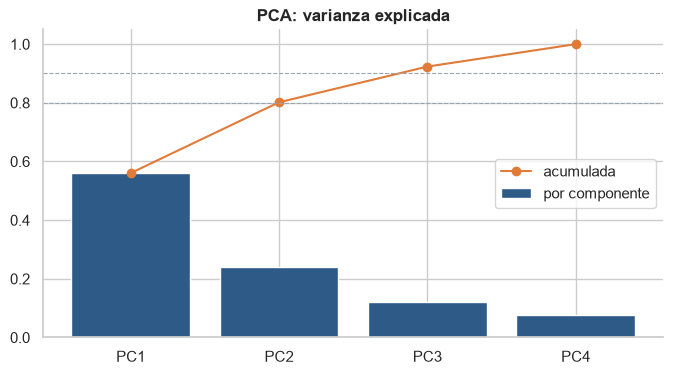

In [3]:
pca = ajustar_pca(Z)
varianza = tabla_varianza_pca(pca)
display(varianza)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(varianza.index, varianza["varianza_explicada"], color=COLOR_PRINCIPAL, label="por componente")
ax.plot(varianza.index, varianza["varianza_acumulada"], marker="o", color=COLOR_SECUNDARIO, label="acumulada")
for umbral in (0.8, 0.9):
    ax.axhline(umbral, ls="--", lw=0.8, color=COLOR_NEUTRO)
ax.set_ylim(0, 1.05)
ax.set_title("PCA: varianza explicada")
ax.legend()
guardar_figura(fig, "03_pca_varianza")
plt.show()

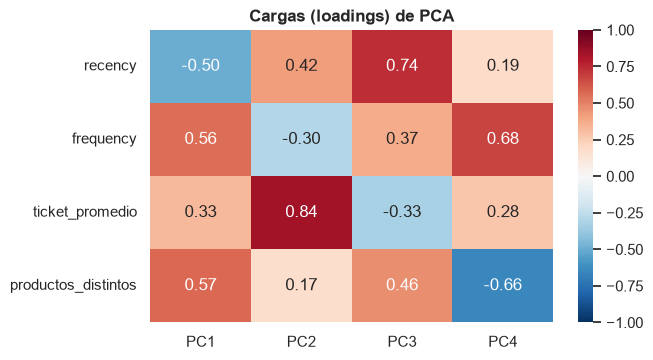

In [4]:
cargas = cargas_pca(pca, VARIABLES_CLUSTERING)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Cargas (loadings) de PCA")
guardar_figura(fig, "03_pca_cargas")
plt.show()

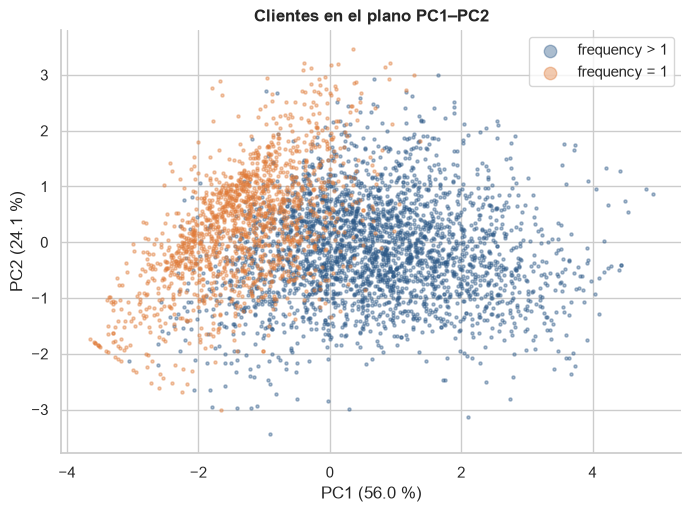

In [5]:
coords_pca = pca.transform(Z)
fig, ax = plt.subplots(figsize=(8, 5.5))
for mascara, color, etiqueta in [(F > 1, COLOR_PRINCIPAL, "frequency > 1"), (F == 1, COLOR_SECUNDARIO, "frequency = 1")]:
    ax.scatter(coords_pca[mascara, 0], coords_pca[mascara, 1], s=5, alpha=0.4, color=color, label=etiqueta)
ax.set_xlabel(f"PC1 ({100 * varianza.iloc[0, 0]:.1f} %)")
ax.set_ylabel(f"PC2 ({100 * varianza.iloc[1, 0]:.1f} %)")
ax.set_title("Clientes en el plano PC1–PC2")
ax.legend(markerscale=4)
guardar_figura(fig, "03_pca_dispersion")
plt.show()

**¿Clusterizar sobre las variables escaladas o sobre componentes PCA?** Con solo 4 variables, usar los 4
componentes equivale a rotar los datos y K-Means daría lo mismo. La comparación con sentido es frente a **2 o 3
componentes**. Ojo: el silhouette calculado *en el espacio reducido* no es comparable, porque al descartar
varianza los puntos parecen más separados. Por eso se mide también en el espacio común `Z` de 4 dimensiones.

In [6]:
filas = []
for n_comp in (2, 3):
    P = ajustar_pca(Z, n_comp).transform(Z)
    for k in (3, 4, 5):
        en_vars = ajustar_kmeans(Z, k).labels_
        en_pcs = ajustar_kmeans(P, k).labels_
        filas.append({"componentes": n_comp, "k": k,
                      "silhouette Z (variables)": metricas_internas(Z, en_vars)["silhouette"],
                      "silhouette Z (PCs)": metricas_internas(Z, en_pcs)["silhouette"],
                      "silhouette en espacio PCA (inflado)": metricas_internas(P, en_pcs)["silhouette"],
                      "ARI variables vs PCs": ari(en_vars, en_pcs)})
pd.DataFrame(filas)

,componentes,k,silhouette Z (variables),silhouette Z (PCs),silhouette en espacio PCA (inflado),ARI variables vs PCs
0,2,3,0.258,0.258,0.356,0.946
1,2,4,0.240,0.235,0.341,0.817
2,2,5,0.232,0.229,0.349,0.862
3,3,3,0.258,0.258,0.287,0.947
4,3,4,0.240,0.236,0.265,0.887
5,3,5,0.232,0.231,0.263,0.918


**Hallazgos — PCA**

- **PC1 explica el 56,0 %** de la varianza y PC2 el 24,1 %: juntas suman el **80,2 %**, y con PC3 se llega al 92,3 %.
- **PC1 = actividad / valor del cliente:** cargas positivas de productos distintos (0,57), frequency (0,56) y ticket
  (0,33), y negativa de recency (−0,50). Un PC1 alto es un cliente que compra a menudo, variado y hace poco.
- **PC2 = tamaño del pedido frente a frecuencia:** dominado por el ticket promedio (0,84), con recency positiva (0,42) y
  frequency negativa (−0,30). Un PC2 alto es un cliente de pedidos grandes pero esporádicos.
- En el plano PC1–PC2 los clientes con frequency = 1 se concentran en el lado de baja actividad (PC1 negativo), con un
  borde recto característico: es la proyección del plano de empates de la sección 1. Se solapan en parte con los
  recurrentes, así que no forman un grupo separado.
- **Variables escaladas frente a PCA:** medido en el espacio común `Z`, clusterizar sobre 2 o 3 componentes da un
  silhouette igual o algo peor (0,229–0,258 frente a 0,232–0,258). El silhouette calculado en el propio espacio PCA
  sale **inflado** (0,263–0,356) porque ignora la varianza descartada. **Decisión:** clusterizar sobre las 4 variables
  escaladas (con 4 dimensiones no hay maldición de la dimensionalidad que justifique reducir) y usar PCA para
  **interpretar y visualizar**.

## 3. K-Means: número de clusters (k = 2..10)

In [7]:
barrido = barrido_kmeans(Z, K)
barrido

,k,inercia,silhouette,davies_bouldin,calinski_harabasz,pct_cluster_menor
0,2,"10,797.047",0.326,1.178,"2,601.498",41.836
1,3,"8,641.696",0.258,1.288,"2,163.685",29.209
2,4,"7,398.559",0.240,1.282,"1,926.403",20.537
3,5,"6,582.458",0.232,1.261,"1,757.396",17.021
4,6,"6,004.485",0.226,1.277,"1,624.014",11.355
5,7,"5,590.857",0.218,1.274,"1,506.377",11.124
6,8,"5,223.320",0.211,1.243,"1,425.092",9.366
7,9,"4,941.405",0.209,1.244,"1,348.558",8.002
8,10,"4,683.470",0.212,1.227,"1,290.842",3.446


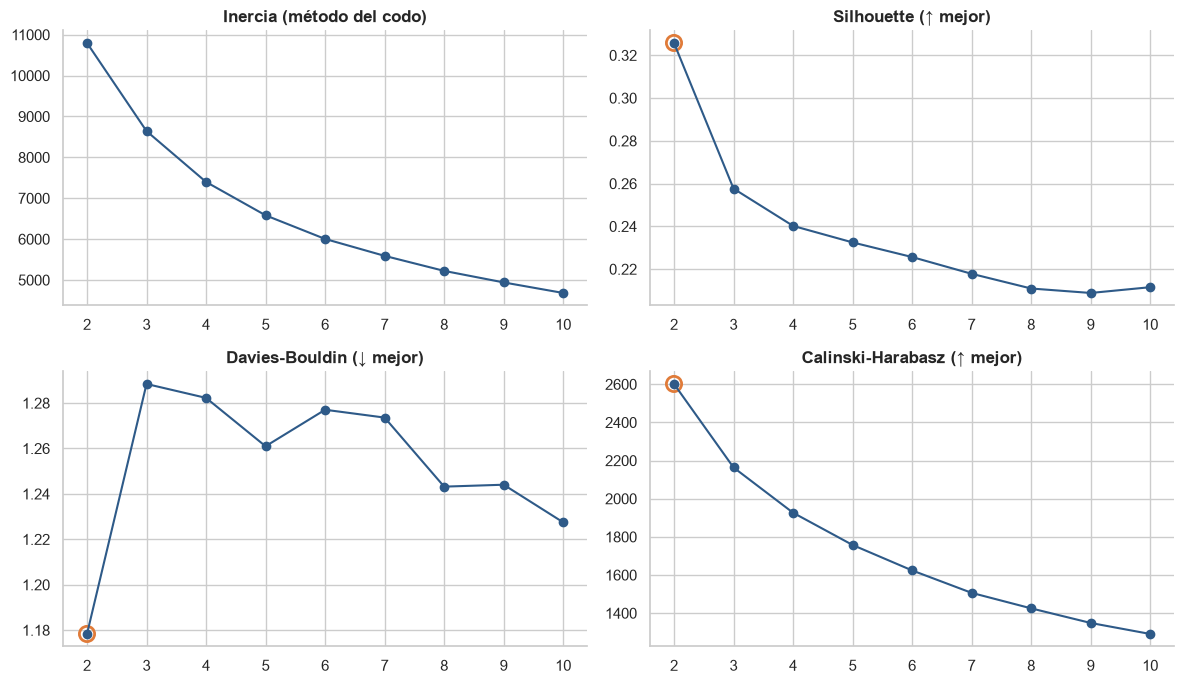

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (col, titulo, mejor) in zip(axes.flat, [("inercia", "Inercia (método del codo)", None),
                                                ("silhouette", "Silhouette (↑ mejor)", "max"),
                                                ("davies_bouldin", "Davies-Bouldin (↓ mejor)", "min"),
                                                ("calinski_harabasz", "Calinski-Harabasz (↑ mejor)", "max")]):
    ax.plot(barrido["k"], barrido[col], marker="o", color=COLOR_PRINCIPAL)
    if mejor:
        fila = barrido.loc[barrido[col].idxmax() if mejor == "max" else barrido[col].idxmin()]
        ax.scatter([fila["k"]], [fila[col]], s=120, facecolors="none", edgecolors=COLOR_SECUNDARIO, linewidths=2)
    ax.set_title(titulo)
    ax.set_xticks(K)
fig.tight_layout()
guardar_figura(fig, "03_kmeans_metricas")
plt.show()

**Estabilidad por k.** Para cada k se reajusta K-Means en 30 submuestras del 80 % de los clientes (sin reemplazo) y
se compara la partición de esos clientes con la del modelo completo mediante el ARI (1 = idéntica). Un k es útil
si sus segmentos no cambian al cambiar un poco los datos.

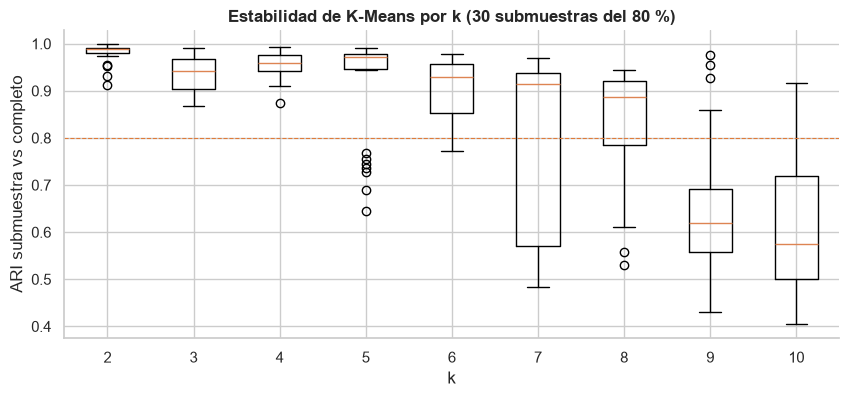

,k,silhouette,davies_bouldin,estabilidad_mediana,estabilidad_p10,ARI_frequency_descuantizada,pct_cluster_menor
0,2,0.326,1.178,0.988,0.955,0.943,41.836
1,3,0.258,1.288,0.942,0.888,0.945,29.209
2,4,0.240,1.282,0.959,0.933,0.941,20.537
3,5,0.232,1.261,0.971,0.736,0.936,17.021
4,6,0.226,1.277,0.928,0.825,0.918,11.355
5,7,0.218,1.274,0.914,0.516,0.917,11.124
6,8,0.211,1.243,0.888,0.697,0.884,9.366
7,9,0.209,1.244,0.620,0.530,0.830,8.002
8,10,0.212,1.227,0.574,0.443,0.841,3.446


In [9]:
estabilidad_k = {k: estabilidad_submuestreo(Z, lambda x, s, k=k: ajustar_kmeans(x, k, s).labels_, n_repeticiones=30) for k in K}
barrido["estabilidad_mediana"] = [np.median(estabilidad_k[k]) for k in K]
barrido["estabilidad_p10"] = [np.percentile(estabilidad_k[k], 10) for k in K]
barrido["ARI_frequency_descuantizada"] = [ari(ajustar_kmeans(Z, k).labels_, ajustar_kmeans(Z_desc, k).labels_) for k in K]

fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([estabilidad_k[k] for k in K], tick_labels=K)
ax.axhline(0.8, ls="--", lw=0.8, color=COLOR_SECUNDARIO)
ax.set_xlabel("k")
ax.set_ylabel("ARI submuestra vs completo")
ax.set_title("Estabilidad de K-Means por k (30 submuestras del 80 %)")
guardar_figura(fig, "03_kmeans_estabilidad")
plt.show()
barrido[["k", "silhouette", "davies_bouldin", "estabilidad_mediana", "estabilidad_p10", "ARI_frequency_descuantizada", "pct_cluster_menor"]]

**Hallazgos — K-Means**

- **Las métricas internas favorecen k = 2:** silhouette 0,326, Davies-Bouldin 1,178 y Calinski-Harabasz 2.601 son los
  mejores del barrido. A partir de ahí el silhouette baja de forma continua (0,258 en k = 3 hasta 0,209–0,212 en
  k = 9–10) y el codo de la inercia no es nítido.
- Que el silhouette caiga monótonamente con k, con valores entre 0,2 y 0,33, indica una **nube continua sin grupos
  naturales bien separados**. En esa situación las métricas internas siempre premian el k más pequeño. No es evidencia
  de que existan "dos tipos" de clientes.
- **Estabilidad:** hasta k = 6 la mediana del ARI es ≥ 0,92, pero el **percentil 10** separa los candidatos: k = 4
  0,933, k = 5 **0,736**, k = 6 0,825. Desde k = 9 los segmentos se rehacen en cada submuestra (mediana ≤ 0,62).
- **Empates:** al descuantizar frequency, K-Means con k = 2..6 da casi la misma partición (ARI 0,918–0,945). K-Means
  no depende de la densidad y los empates apenas le afectan.